# Parkinson's Disease Detection

**Made by:**

TS SHARAN-25BCA7670

SJ VISWAK-25BCE7873

# Mounting Google Drive

In [140]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Define Dataset Paths

In [141]:
spiral_train_path = "/content/drive/MyDrive/Parkinson_Disease_Detection/Spiral/Train"
spiral_test_path  = "/content/drive/MyDrive/Parkinson_Disease_Detection/Spiral/Test"
wave_train_path = "/content/drive/MyDrive/parkinson_dataset/wave/train"
wave_test_path    = "/content/drive/MyDrive/Parkinson_Disease_Detection/Wave/Test"

# Spiral Model:

**Processing**

In [142]:
import tensorflow as tf
from tensorflow.keras import layers, models

img_height, img_width = 128, 128
batch_size = 32

**Train**

In [143]:
spiral_train = tf.keras.utils.image_dataset_from_directory(
    spiral_train_path,
    image_size=(img_height, img_width),
    batch_size=batch_size,
    label_mode="binary"
)

Found 73 files belonging to 2 classes.


**Test**

In [144]:
spiral_test = tf.keras.utils.image_dataset_from_directory(
    spiral_test_path,
    image_size=(img_height, img_width),
    batch_size=batch_size,
    label_mode="binary"
)

Found 30 files belonging to 2 classes.


**Normalize**

In [145]:
normalization_layer = tf.keras.layers.Rescaling(1./255)
spiral_train = spiral_train.map(lambda x, y: (normalization_layer(x), y))
spiral_test = spiral_test.map(lambda x, y: (normalization_layer(x), y))

**Data Augmentation**

In [146]:
# Data augmentation
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.2),
    layers.RandomZoom(0.2),
])

**EfficientNetB0 base**

In [147]:
base_model_spiral = tf.keras.applications.EfficientNetB0(
    input_shape=(img_height, img_width, 3),
    include_top=False,
    weights="imagenet"
)

**Fine-tune last 20 layers**

In [148]:
base_model_spiral.trainable = True
for layer in base_model_spiral.layers[:-20]:
    layer.trainable = False

**Compile**

In [149]:
spiral_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

**Train**

In [150]:
early_stop = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
spiral_history = spiral_model.fit(spiral_train, validation_data=spiral_test, epochs=20, callbacks=[early_stop])

Epoch 1/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 701ms/step - accuracy: 0.5068 - loss: 0.6920 - val_accuracy: 0.5000 - val_loss: 0.6921
Epoch 2/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 587ms/step - accuracy: 0.5068 - loss: 0.6918 - val_accuracy: 0.5000 - val_loss: 0.6921
Epoch 3/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 3s 918ms/step - accuracy: 0.5068 - loss: 0.6917 - val_accuracy: 0.5000 - val_loss: 0.6921
Epoch 4/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 555ms/step - accuracy: 0.5068 - loss: 0.6916 - val_accuracy: 0.5000 - val_loss: 0.6922
Epoch 5/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 561ms/step - accuracy: 0.5068 - loss: 0.6917 - val_accuracy: 0.5000 - val_loss: 0.6922


**Evaluation**

In [151]:
loss, acc = spiral_model.evaluate(spiral_test)
print(f"Spiral Test Accuracy: {acc:.2f}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 293ms/step - accuracy: 0.5000 - loss: 0.6921
Spiral Test Accuracy: 0.50


**Saving Model**

In [152]:
spiral_model.save("/content/drive/MyDrive/Parkinson_Disease_Detection/Spiral_Model.h5")

# Wave Model:

**Defining paths**

In [153]:
wave_train_path = "/content/drive/MyDrive/Parkinson_Disease_Detection/Wave/Train"
wave_test_path  = "/content/drive/MyDrive/Parkinson_Disease_Detection/Wave/Test"

**Train**

In [154]:
wave_train = tf.keras.utils.image_dataset_from_directory(
    wave_train_path,
    image_size=(img_height, img_width),
    batch_size=batch_size,
    label_mode="binary"
)

Found 72 files belonging to 2 classes.


**Test**

In [155]:
wave_test = tf.keras.utils.image_dataset_from_directory(
    wave_test_path,
    image_size=(img_height, img_width),
    batch_size=batch_size,
    label_mode="binary"
)

Found 30 files belonging to 2 classes.


**Normalize**

In [156]:
wave_train = wave_train.map(lambda x, y: (normalization_layer(x), y))
wave_test = wave_test.map(lambda x, y: (normalization_layer(x), y))

**EfficientNetB0 base**

In [157]:
base_model_wave = tf.keras.applications.EfficientNetB0(
    input_shape=(img_height, img_width, 3),
    include_top=False,
    weights="imagenet"
)

**Fine-tune last 20 layers**

In [158]:
base_model_wave.trainable = True
for layer in base_model_wave.layers[:-20]:
    layer.trainable = False

**Build Model**


In [159]:
wave_model = models.Sequential([
    data_augmentation,
    base_model_wave,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.5),
    layers.Dense(1, activation="sigmoid")
])

**Compile**

In [160]:
wave_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

**Model Training**

In [161]:
wave_history = wave_model.fit(wave_train, validation_data=wave_test, epochs=20, callbacks=[early_stop])

Epoch 1/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 22s 2s/step - accuracy: 0.5278 - loss: 0.7055 - val_accuracy: 0.5000 - val_loss: 0.7132
Epoch 2/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 3s 821ms/step - accuracy: 0.5972 - loss: 0.7021 - val_accuracy: 0.5000 - val_loss: 0.7125
Epoch 3/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 1s/step - accuracy: 0.3194 - loss: 0.7702 - val_accuracy: 0.5000 - val_loss: 0.7116


**Evaluate**

In [162]:
loss, acc = wave_model.evaluate(wave_test)
print(f"Wave Test Accuracy: {acc:.2f}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 829ms/step - accuracy: 0.5000 - loss: 0.7132
Wave Test Accuracy: 0.50


**Saving Model**

In [163]:
wave_model.save("/content/drive/MyDrive/Parkinson_Disease_Detection/Wave_model.h5")

**Accuracy**

In [164]:
loss, acc = model.evaluate(test_ds)
print(f"Test Accuracy: {acc:.2f}")


1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - accuracy: 0.7000 - loss: 0.6111
Test Accuracy: 0.70


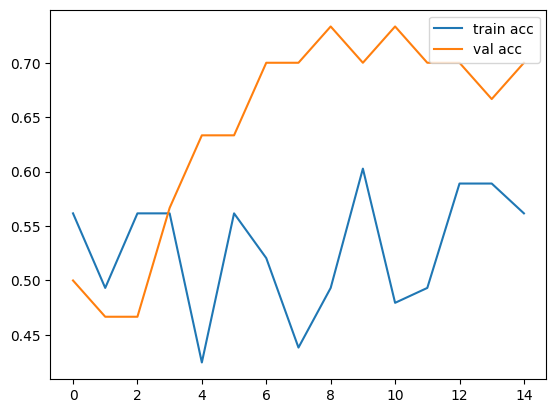

In [165]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'], label='train acc')
plt.plot(history.history['val_accuracy'], label='val acc')
plt.legend()
plt.show()
